In [1]:
using JARS


sa_file = JIO.load_file(joinpath(homedir(), "testdata_JARS","sa_raw_data.h5"))

system_sizes = sa_file["system"]["sizes"]
step = 10

t = sa_file["integration_info"]["save_tax"][1:step:end]

x = JIO.collect_over_frames("x",sa_file,type=1, step=step)

y = JIO.collect_over_frames("y",sa_file,type=1, step = step)

z = JIO.collect_over_frames("z",sa_file,type=1,step=step)

vx = JIO.collect_over_frames("vx",sa_file,type=1, step=step)

vy = JIO.collect_over_frames("vy",sa_file,type=1, step = step)

vz = JIO.collect_over_frames("vz",sa_file,type=1,step=step)

px = JIO.collect_over_frames("px",sa_file,type=1, step=step)

py = JIO.collect_over_frames("py",sa_file,type=1, step = step)

pz = JIO.collect_over_frames("pz",sa_file,type=1, step = step)



[ Info: Precompiling JARS [463ed9ea-d574-4d46-b957-79042c805606] (caches not reused: 1 for different Julia build configuration, 1 for file size changed)
Precompiling packages...
   4.3 s  ✓ JARS
  1 dependency successfully precompiled in 5 seconds. 347 already precompiled.
┌ Warning: File likely not written by JLD2. Skipping header verification.
└ @ JLD2 ~/.julia/packages/JLD2/rm5a0/src/file_header.jl:21


704×501 Matrix{Float64}:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0

In [2]:
msd = JOB.MSD(t,x, y, z)

vop = JOB.vicsek_order_parameter(t, px, py, pz)
vvop = JOB.vicsek_order_parameter(t, vx, vy, vz)

rBins = JOB.linear_bins(3, 100)
Cvv_r = JOB.spatial_correlation(rBins, x, y, z, vx, vy, vz; RMS_normalization=true, system_sizes=system_sizes)

Cnn_r = JOB.spatial_correlation(rBins, x, y, z, px, py, pz; system_sizes=system_sizes)

spatial correlation 100%|█████████████████| Time: 0:00:04 ( 9.60 ms/it)
spatial correlation 100%|█████████████████| Time: 0:00:04 ( 9.05 ms/it)


Dict{String, Vector{Float64}} with 2 entries:
  "r" => [0.0, 1.5, 4.5, 7.5, 10.5, 13.5, 16.5, 19.5, 22.5, 25.5  …  70.5, 73.5…
  "C" => [1.0, 0.73488, 0.596461, 0.457492, 0.34154, 0.253315, 0.190549, 0.1416…

In [3]:
using CairoMakie

set_theme!(serif_theme())

function plot_msd!(pos)
    ax = Axis(pos, xscale=log10, yscale=log10, xlabel="lagtime", ylabel=L"\langle r2 \rangle^2")

    ylims!(ax, high=1e0, low=1e-5)

    scatterlines!(ax, msd["lagtime"], msd["msd"])
end
function plot_msd_zoom!(pos)
    ax = Axis(pos, xscale=log10, yscale=log10, xlabel="lagtime", ylabel=L"\langle r2 \rangle^2")

    ylims!(ax, high=1e0, low=1e-2)

    xlims!(ax, low=10^(1.5))

    scatterlines!(ax, msd["lagtime"], msd["msd"])
end

function plot_Cvv_r(pos)
    ax = Axis(pos, xlabel=L"r", ylabel=L"C_{vv}(r)", xticks=0:5:50)

    scatterlines!(ax, Cvv_r["r"], Cvv_r["C"])
end

function plot_Cnn_r(pos)
    ax = Axis(pos, xlabel=L"r", ylabel=L"C_{n}(r)", xticks=0:5:50)

    scatterlines!(ax, Cnn_r["r"], Cnn_r["C"])
end



plot_Cnn_r (generic function with 1 method)

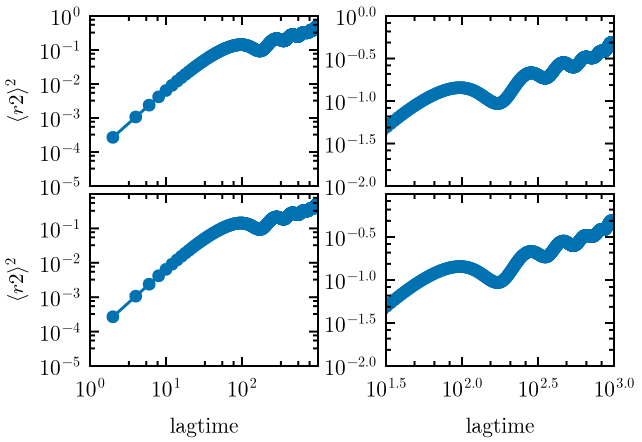

CairoMakie.Screen{IMAGE}


In [4]:
f = Figure1col()

plot_msd!(f[1,1])
plot_msd_zoom!(f[1,2])
plot_msd!(f[2,1])
plot_msd_zoom!(f[2,2])

# plot_msd!(f[1,3])
# plot_msd!(f[2,3])

compress_whitespace!(f,sharex=true, sharey=false, shareylabel=true)
save(joinpath(pwd(),"msd_1col.pdf"), f; backend = CairoMakie)
display(f)

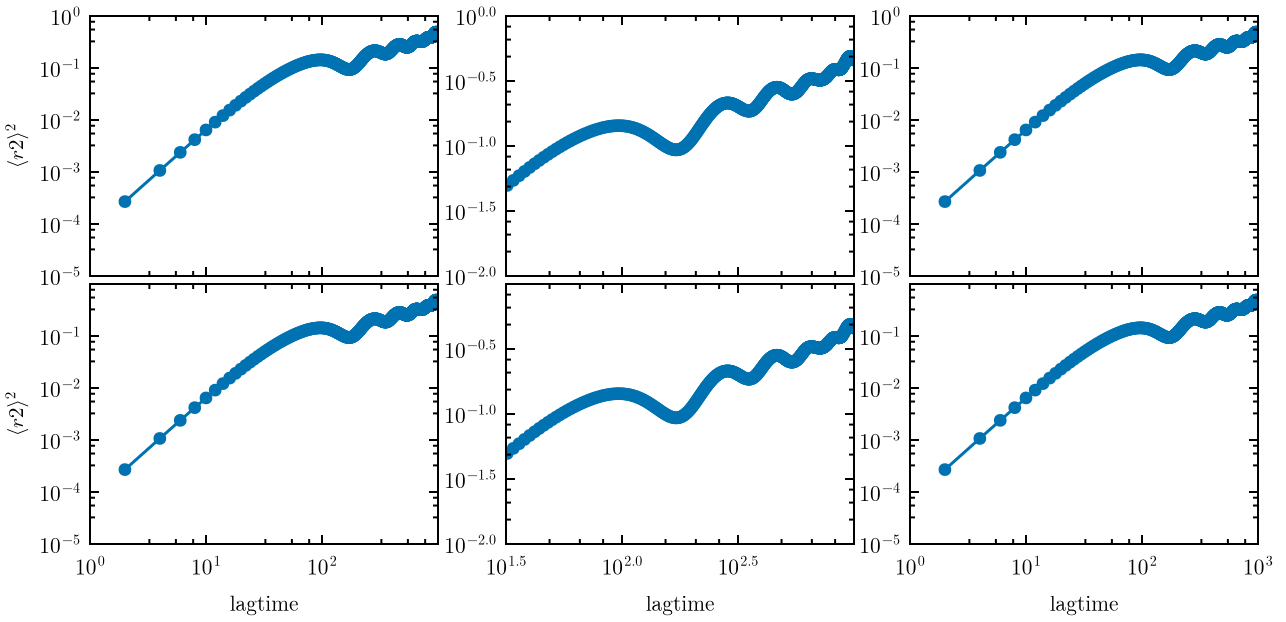

CairoMakie.Screen{IMAGE}


In [5]:
f = Figure2col()

plot_msd!(f[1,1])
plot_msd_zoom!(f[1,2])
plot_msd!(f[2,1])
plot_msd_zoom!(f[2,2])

plot_msd!(f[1,3])
plot_msd!(f[2,3])

compress_whitespace!(f,sharex=true, sharey=false, shareylabel=true)
save(joinpath(pwd(),"msd_2col.pdf"), f; backend = CairoMakie)
display(f)

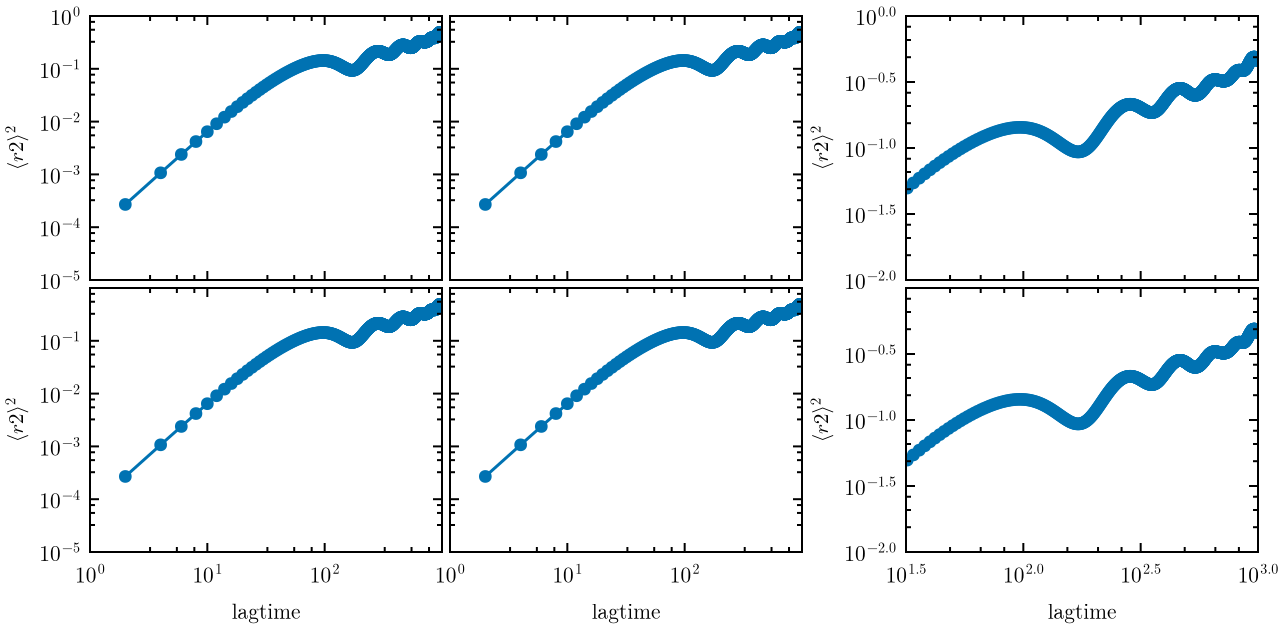

In [6]:
f = Figure2col()
a = plot_msd!(f[1, 1]);  b = plot_msd!(f[1, 2]);  c = plot_msd_zoom!(f[1, 3])
d = plot_msd!(f[2, 1]);  e = plot_msd!(f[2, 2]);  g = plot_msd_zoom!(f[2, 3])

share!(f; x = true, y = true, cells = (1:2, 1:2))  
share!(f; x=true, cells = (1:2, 3))        
compress_whitespace!(f)

colgap!(f.layout, 2, 4)     
adjust_height!(f)

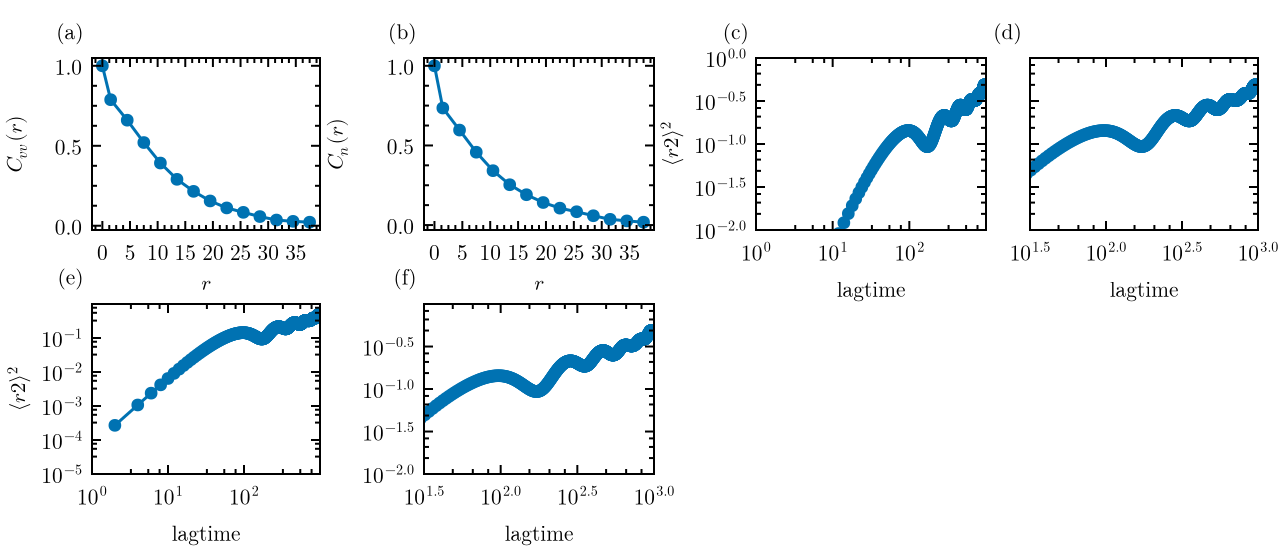

CairoMakie.Screen{PDF}


In [17]:
f = Figure2col()
a = plot_Cvv_r(f[1, 1]);  b = plot_Cnn_r(f[1, 2]); 
d = plot_msd!(f[2, 1]);  e = plot_msd_zoom!(f[2, 2]);
g = plot_msd!(f[1, 3]);  h = plot_msd_zoom!(f[1, 4]);

 share!(f; x = true, y = true, cells = (1, 3:4)) 
  
 share!(f; x = false, y = false, ylabel=true, cells = (2, 1:2)) 
label_panels!(f,inside=false)
compress_whitespace!(f)
rowgap!(f.layout,1,-20)
adjust_height!(f)
display(f)
save(joinpath(pwd(),"diverse_2col.pdf"), f; backend = CairoMakie)